<a href="https://colab.research.google.com/github/aline-kuster/Projeto-pluma/blob/main/parque_pluma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Célula 1: Instalação das dependências do SAM 2 e visualização
!pip install -q "git+https://github.com/facebookresearch/segment-anything-2.git"
!pip install -q huggingface_hub opencv-python-headless matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.0/117.0 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 9.0 MB/s eta 0:00:00


In [3]:
# Célula 2: Download do Checkpoint e Configuração
import os
from huggingface_hub import hf_hub_download

checkpoint_path = hf_hub_download(
    repo_id="facebook/sam2-hiera-large",
    filename="sam2_hiera_large.pt",
    local_dir="checkpoints"
)

!mkdir -p configs/sam2
!wget -q -O configs/sam2/sam2_hiera_l.yaml https://raw.githubusercontent.com/facebookresearch/sam2/main/sam2/configs/sam2/sam2_hiera_l.yaml

print("Ficheiro descarregado:", checkpoint_path)
print("Tamanho:", round(os.path.getsize(checkpoint_path) / (1024 * 1024), 2), "MB")

sam2_hiera_large.pt: reconstructing file:   0%|          |  0.00B /  898MB            

sam2_hiera_large.pt: downloading bytes:           |  0.00B            

Ficheiro descarregado: /content/checkpoints/sam2_hiera_large.pt
Tamanho: 856.35 MB


Selecione e envie a imagem do incêndio:


Saving 9794074.webp to 9794074.webp
Dimensões da imagem: Largura (X) = 860px, Altura (Y) = 484px


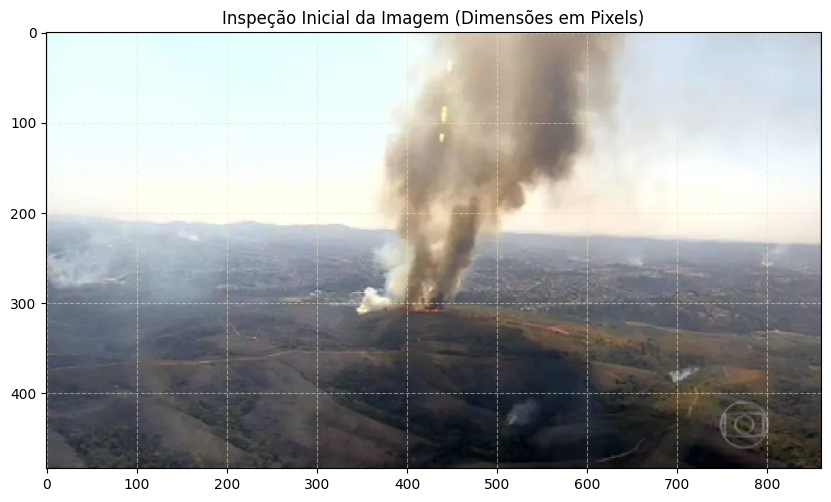

In [4]:
# Célula 3: Carregamento da imagem e inspeção de dimensões
import cv2
import matplotlib.pyplot as plt
from google.colab import files

print("Selecione e envie a imagem do incêndio:")
uploaded = files.upload()
IMAGE_PATH = list(uploaded.keys())[0]

img_bgr = cv2.imread(IMAGE_PATH)
if img_bgr is None:
    raise FileNotFoundError(f"Não foi possível carregar a imagem: {IMAGE_PATH}")

img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_h, img_w, _ = img.shape

print(f"Dimensões da imagem: Largura (X) = {img_w}px, Altura (Y) = {img_h}px")

plt.figure(figsize=(10, 6))
plt.imshow(img)
plt.grid(True, color='yellow', linestyle='--', alpha=0.5)
plt.title("Inspeção Inicial da Imagem (Dimensões em Pixels)")
plt.show()

In [5]:
# Célula 4: Inicialização do SAM 2
import torch
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

device = "cuda" if torch.cuda.is_available() else "cpu"
model_cfg = "configs/sam2/sam2_hiera_l.yaml"

sam2_model = build_sam2(model_cfg, checkpoint_path, device=device)
predictor = SAM2ImagePredictor(sam2_model)

predictor.set_image(img)
print(f"Modelo SAM 2 carregado com sucesso em: {device.upper()}")

Modelo SAM 2 carregado com sucesso em: CPU


In [8]:
# Célula 5: Função de visualização em 3 painéis e conversão de coordenadas
import numpy as np

def rel_pt(x_rel, y_rel):
    """Converte coordenadas relativas (0 a 1) para píxeis absolutos."""
    return [int(x_rel * img_w), int(y_rel * img_h)]

def rel_box(x1_rel, y1_rel, x2_rel, y2_rel):
    """Converte caixa relativa para píxeis absolutos [x1, y1, x2, y2]."""
    return np.array([int(x1_rel * img_w), int(y1_rel * img_h), int(x2_rel * img_w), int(y2_rel * img_h)])

def exibir_tres_paineis(titulo, mask, box=None, points=None, labels=None):
    """Gera a visualização lado a lado em 3 painéis."""
    overlay = img.copy()
    cor_mascara = np.array([255, 0, 0], dtype=np.uint8) # Vermelho
    overlay[mask] = (overlay[mask] * 0.5 + cor_mascara * 0.5).astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Painel 1: Imagem Original + Prompts
    axes[0].imshow(img)
    axes[0].set_title(f"1. Imagem Original + Prompts\n({titulo})", fontsize=10)
    axes[0].axis("off")

    if box is not None:
        bx1, by1, bx2, by2 = box
        rect = plt.Rectangle((bx1, by1), bx2 - bx1, by2 - by1, fill=False, edgecolor='cyan', linewidth=2)
        axes[0].add_patch(rect)

    if points is not None and labels is not None:
        pos = points[labels == 1]
        neg = points[labels == 0]
        if len(pos) > 0:
            axes[0].scatter(pos[:, 0], pos[:, 1], color='lime', s=90, edgecolors='black', label='Positivo (1)')
        if len(neg) > 0:
            axes[0].scatter(neg[:, 0], neg[:, 1], color='red', s=90, edgecolors='black', label='Negativo (0)')
        axes[0].legend(loc='lower right')

    # Painel 2: Máscara Binária
    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("2. Máscara Binária", fontsize=10)
    axes[1].axis("off")

    # Painel 3: Máscara Sobreposta
    axes[2].imshow(overlay)
    axes[2].set_title("3. Máscara Sobreposta", fontsize=10)
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

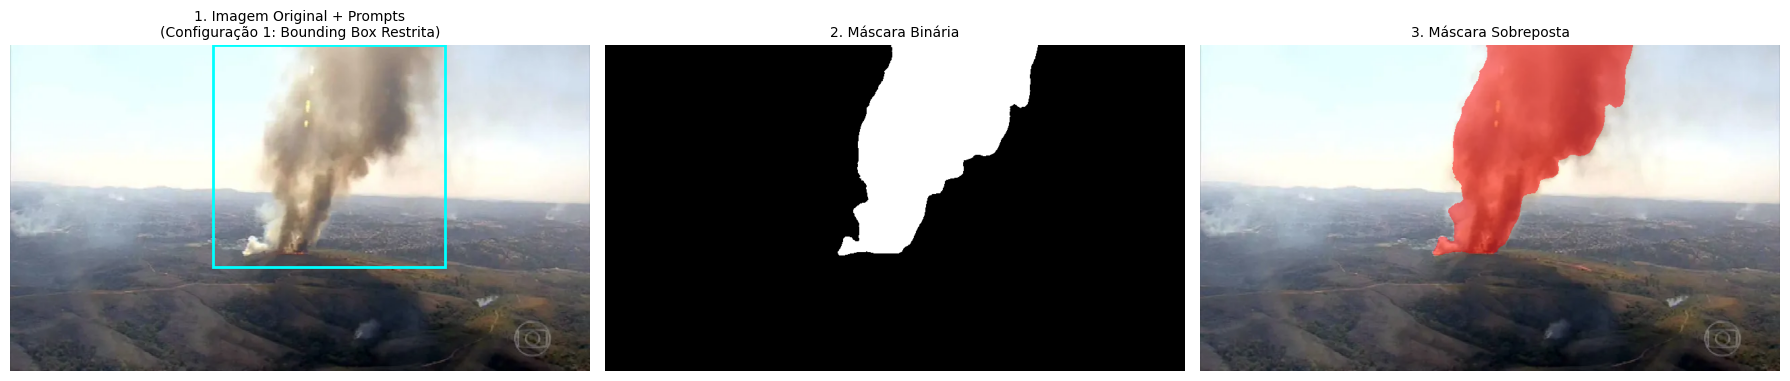

In [15]:
# Célula 6: Teste 1 (Apenas Bounding Box)
box_cfg1 = rel_box(0.35, 0.00, 0.75, 0.68)

with torch.inference_mode():
    masks1, scores1, _ = predictor.predict(
        box=box_cfg1,
        multimask_output=False
    )

mask1 = masks1[0].astype(bool)
exibir_tres_paineis("Configuração 1: Bounding Box Restrita", mask1, box=box_cfg1)

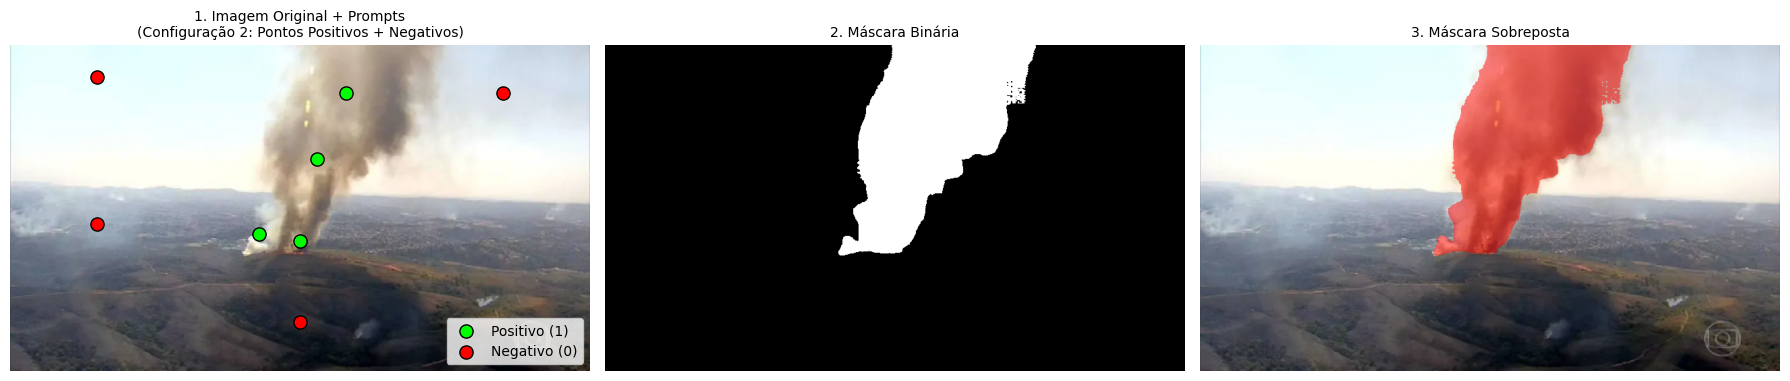

In [10]:
# Célula 7: Teste 2 (Pontos Positivos e Negativos)
pts_cfg2 = np.array([
    rel_pt(0.50, 0.60),  # Positivo: Fumo escuro e denso na base
    rel_pt(0.43, 0.58),  # Positivo: Fumo branco adjacente
    rel_pt(0.53, 0.35),  # Positivo: Corpo central da pluma
    rel_pt(0.58, 0.15),  # Positivo: Topo disperso
    rel_pt(0.15, 0.10),  # Negativo: Céu claro (superior esquerdo)
    rel_pt(0.85, 0.15),  # Negativo: Céu claro (superior direito)
    rel_pt(0.50, 0.85),  # Negativo: Terreno/Morros em primeiro plano
    rel_pt(0.15, 0.55)   # Negativo: Névoa/Bruma nos morros à esquerda
])
labels_cfg2 = np.array([1, 1, 1, 1, 0, 0, 0, 0])

with torch.inference_mode():
    masks2, scores2, _ = predictor.predict(
        point_coords=pts_cfg2,
        point_labels=labels_cfg2,
        multimask_output=False
    )

mask2 = masks2[0].astype(bool)
exibir_tres_paineis("Configuração 2: Pontos Positivos + Negativos", mask2, points=pts_cfg2, labels=labels_cfg2)

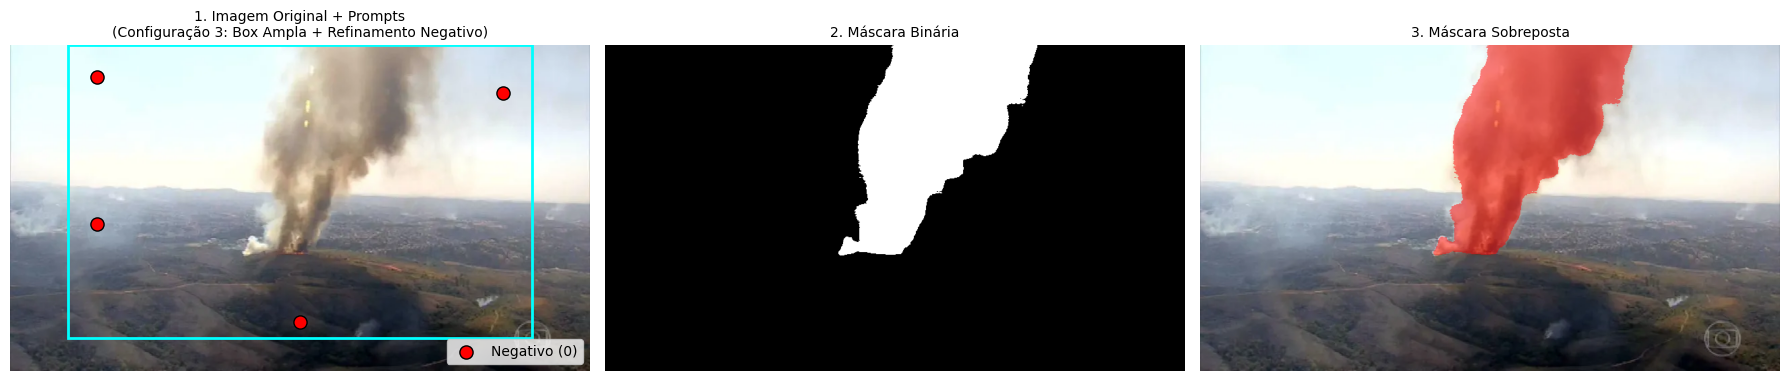

In [11]:
# Célula 8: Teste 3 (Bounding Box + Pontos Negativos de Refinamento)
box_cfg3 = rel_box(0.10, 0.00, 0.90, 0.90)
pts_cfg3 = np.array([
    rel_pt(0.15, 0.10),  # Negativo: Céu
    rel_pt(0.85, 0.15),  # Negativo: Céu
    rel_pt(0.50, 0.85),  # Negativo: Relevo
    rel_pt(0.15, 0.55)   # Negativo: Névoa nos morros
])
labels_cfg3 = np.array([0, 0, 0, 0])

with torch.inference_mode():
    masks3, scores3, _ = predictor.predict(
        point_coords=pts_cfg3,
        point_labels=labels_cfg3,
        box=box_cfg3,
        multimask_output=False
    )

mask3 = masks3[0].astype(bool)
exibir_tres_paineis("Configuração 3: Box Ampla + Refinamento Negativo", mask3, box=box_cfg3, points=pts_cfg3, labels=labels_cfg3)